# Stage 8 – Figures

**Goal:** draw the report figures from the GraphML files, so the pictures show exactly what Gephi would load.

**Reads:** `outputs/graphml/*.graphml`, `outputs/tables/node_metrics_<format>.csv`
**Writes:** `outputs/figures/network_<format>.png`, `network_comparison.png`, `degree_distributions.png`

In [1]:
%run ./library/lib_00_settings.ipynb
%run ./library/lib_06_figures.ipynb
stage_log = get_stage_logger("08_figures")

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
import warnings

graphs_by_format, measures_by_format = {}, {}
with warnings.catch_warnings():
    # The NetworkX ForceAtlas2 code divides by zero for nodes placed at the same point in its first step.
    # It recovers on its own; we hide only this known warning so the notebook output stays readable.
    warnings.filterwarnings("ignore", message="invalid value encountered in divide", category=RuntimeWarning)
    for format_name in FORMATS:
        file_tag = FORMAT_FILE_TAG[format_name]
        graphs_by_format[format_name] = nx.read_graphml(GRAPHML_FOLDER / f"england_men_{file_tag}.graphml")
        measures_by_format[format_name] = read_table(TABLES_FOLDER / f"node_metrics_{file_tag}.csv")
        save_single_network_figure(graphs_by_format[format_name], measures_by_format[format_name], format_name,
                                   FIGURES_FOLDER / f"network_{file_tag}.png")
        stage_log.info("wrote network_%s.png", file_tag)
    save_comparison_figure(graphs_by_format, measures_by_format, FIGURES_FOLDER / "network_comparison.png")
    save_degree_distribution_figure(measures_by_format, FIGURES_FOLDER / "degree_distributions.png")
stage_log.info("wrote network_comparison.png, degree_distributions.png")

2026-11-16 20:27:35,500 INFO batnet.08_figures: wrote network_test.png


2026-11-16 20:27:35,981 INFO batnet.08_figures: wrote network_odi.png


2026-11-16 20:27:36,430 INFO batnet.08_figures: wrote network_t20i.png


2026-11-16 20:27:37,633 INFO batnet.08_figures: wrote network_comparison.png, degree_distributions.png


### Preview

The full-size network figures are large, so we preview only the small degree-distribution figure here.
Open `outputs/figures/network_comparison.png` to see the networks.

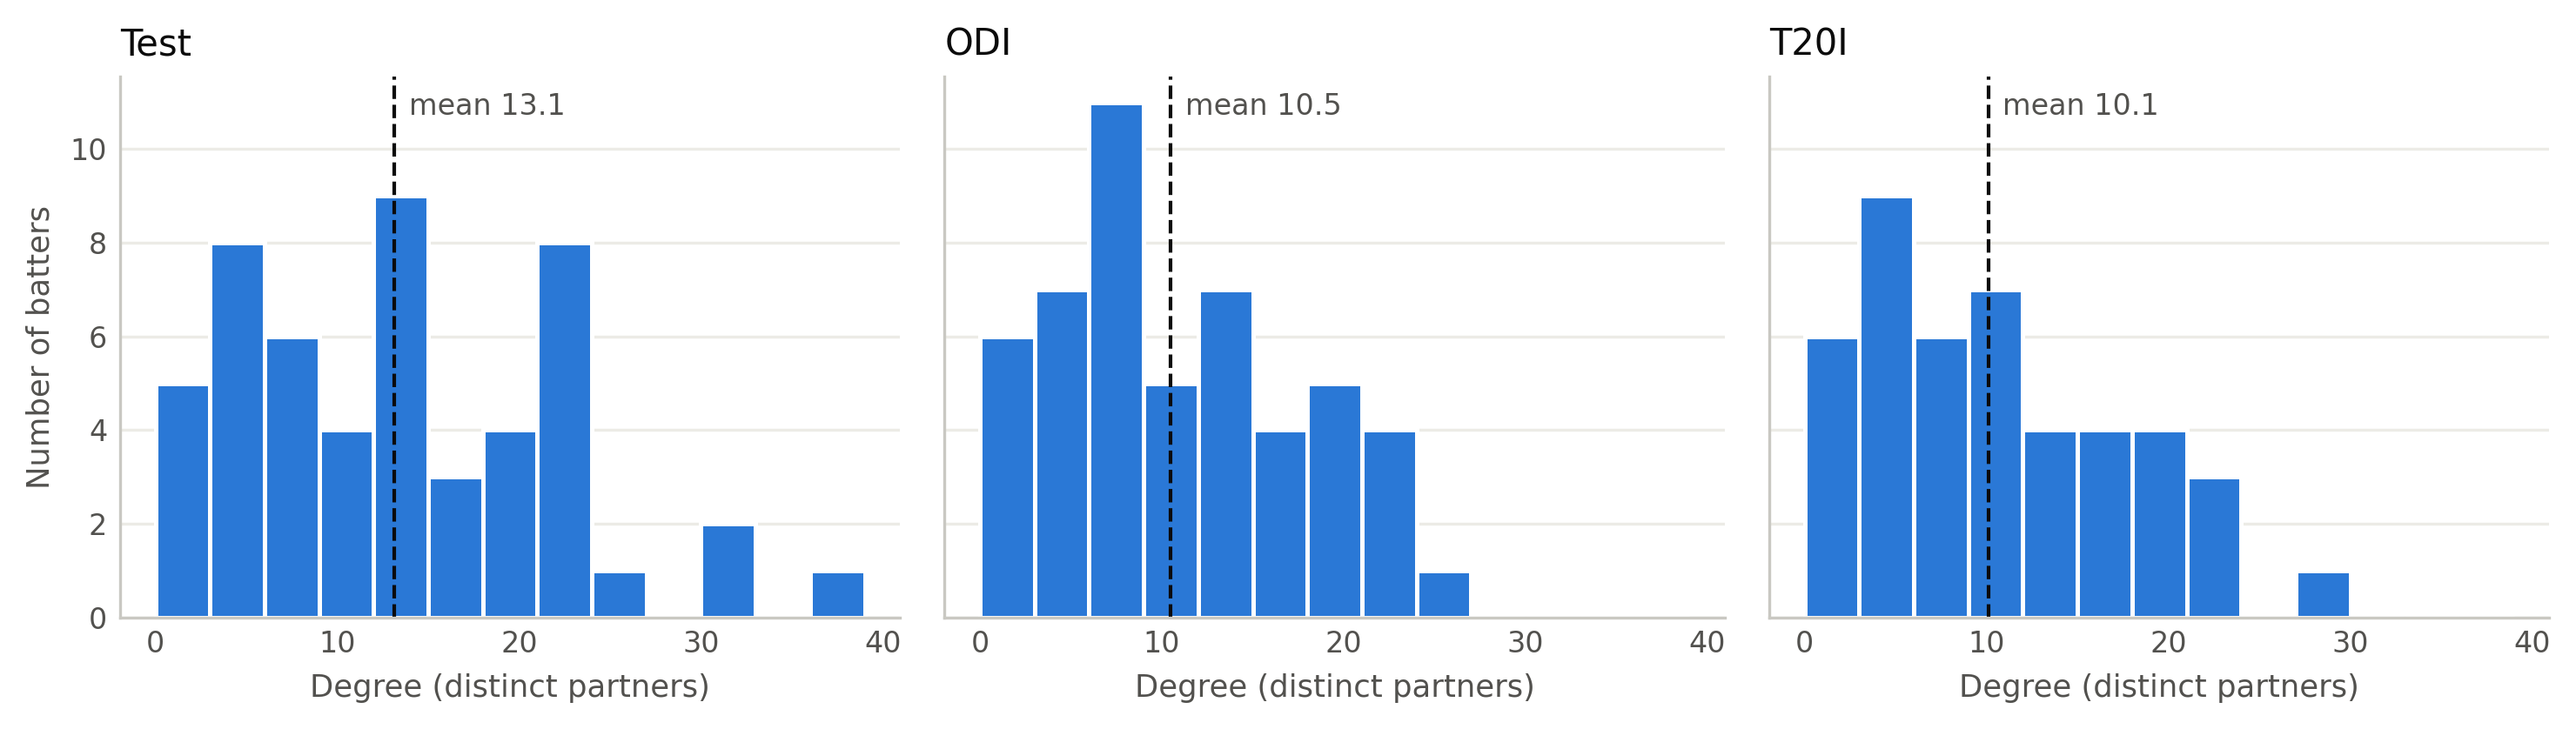

In [3]:
from IPython.display import Image
Image(filename=str(FIGURES_FOLDER / "degree_distributions.png"), width=700)